# 4.2.- Función de Activación: Sigmoide, tanh, ReLU y Leaky ReLU


1. **Sigmoid:** suaviza la salida entre 0 y 1.  
2. **Tanh:** similar a sigmoid pero centrada en 0.  
3. **ReLU:** activa solo valores positivos (rápida y muy usada).  
4. **Leaky ReLU:** versión de ReLU que evita neuronas “muertas”.

Usaremos el mismo dataset no lineal $y = \sin(2x) + \text{ruido}$ para observar cómo cada activación modela la forma de la función.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(33)
tf.random.set_seed(33)
plt.rcParams["figure.figsize"] = (12, 6)

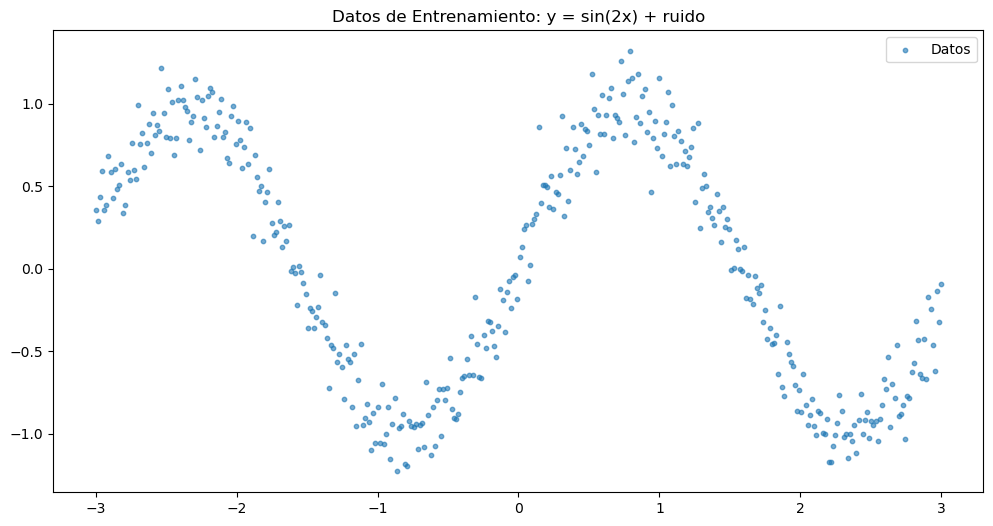

In [2]:
# Datos sintéticos (regresión no lineal)
np.random.seed(42)
X = np.linspace(-3, 3, 400).reshape(-1, 1).astype("float32")
y = np.sin(2 * X) + 0.15 * np.random.normal(size=X.shape).astype("float32")

plt.scatter(X, y, s=10, alpha=0.6, label="Datos")
plt.title("Datos de Entrenamiento: y = sin(2x) + ruido")
plt.legend()
plt.show()

## Sigmoide
Función:
$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

- **Rango**: $(0, 1)$  
- **Propiedades**: Buena para probabilidades, pero se satura fuera de $[-5, 5]$.

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


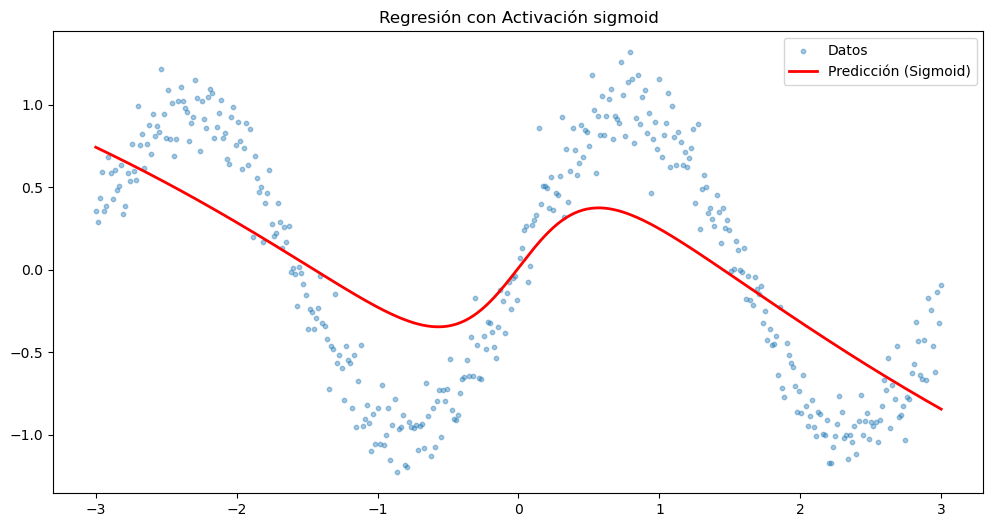

In [7]:
# Modelo con activación sigmoid
model_sigmoid = keras.Sequential([
    keras.Input(shape=(1,)),
    layers.Dense(16, activation="sigmoid"),
    layers.Dense(1)
])

model_sigmoid.compile(optimizer='adam', loss='mse')
model_sigmoid.fit(X, y, epochs=500, verbose=0)

# Predicción y gráfico
y_hat = model_sigmoid.predict(X)
order = np.argsort(X[:, 0])

plt.scatter(X, y, s=10, alpha=0.4, label="Datos")
plt.plot(X[order], y_hat[order], label="Predicción (Sigmoid)", linewidth=2, color="red")
plt.title("Regresión con Activación sigmoid")
plt.legend()
plt.show()

## tanh
Función:
$$
\tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}}
$$

- **Rango**: $(-1, 1)$  
- **Propiedades**: Centrada en 0, pero se satura en valores grandes de $|z|$.

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


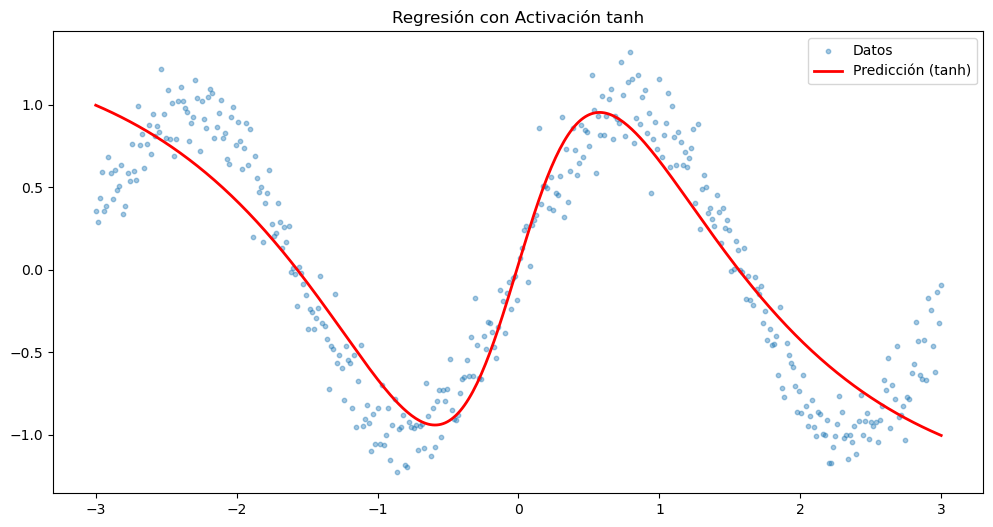

In [4]:
# Modelo con activación tanh
model_tanh = keras.Sequential([
    keras.Input(shape=(1,)),
    layers.Dense(16, activation="tanh"),
    layers.Dense(1)
])

model_tanh.compile(optimizer='adam', loss='mse')
model_tanh.fit(X, y, epochs=300, verbose=0)

# Predicción y gráfico
y_hat = model_tanh.predict(X)
order = np.argsort(X[:, 0])
plt.scatter(X, y, s=10, alpha=0.4, label="Datos")
plt.plot(X[order], y_hat[order], label="Predicción (tanh)", linewidth=2, color="red")
plt.title("Regresión con Activación tanh")
plt.legend()
plt.show()

## ReLU
Función:
$$
\mathrm{ReLU}(z) = \max(0, z)
$$

- **Rango**: $[0, \infty)$  
- **Propiedades**: Rápida de entrenar, pero puede “matar” neuronas con $z < 0$.

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


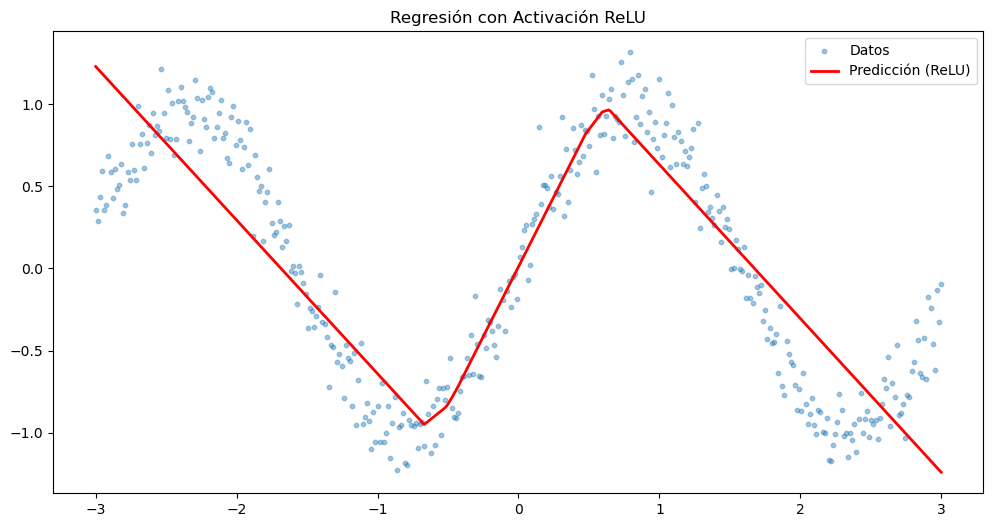

In [5]:
# Modelo con activación ReLU
model_relu = keras.Sequential([
    keras.Input(shape=(1,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

model_relu.compile(optimizer='adam', loss='mse')
model_relu.fit(X, y, epochs=300, verbose=0)

# Predicción y gráfico
y_hat = model_relu.predict(X)
order = np.argsort(X[:, 0])
plt.scatter(X, y, s=10, alpha=0.4, label="Datos")
plt.plot(X[order], y_hat[order], label="Predicción (ReLU)", linewidth=2, color="red")
plt.title("Regresión con Activación ReLU")
plt.legend()
plt.show()

## Leaky ReLU
Función:
$$
\mathrm{LeakyReLU}_\epsilon(z) =
\begin{cases}
z, & z \ge 0 \\
\epsilon z, & z < 0
\end{cases}
$$

- **Rango**: $(-\infty, \infty)$  
- **Propiedades**: Evita neuronas muertas con una pequeña pendiente negativa ($\epsilon$).

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


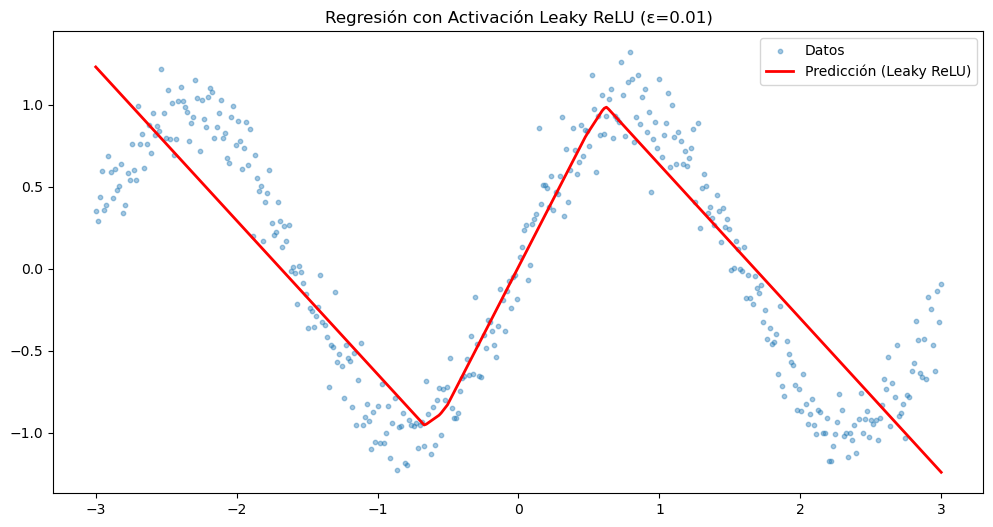

In [6]:
# Modelo con activación Leaky ReLU (α=0.1)
model_lrelu = keras.Sequential([
    keras.Input(shape=(1,)),
    layers.Dense(16),
    layers.LeakyReLU(negative_slope=0.1),
    layers.Dense(1)
])

model_lrelu.compile(optimizer='adam', loss='mse')
model_lrelu.fit(X, y, epochs=300, verbose=0)

# Predicción y gráfico
y_hat = model_lrelu.predict(X)
order = np.argsort(X[:, 0])
plt.scatter(X, y, s=10, alpha=0.4, label="Datos")
plt.plot(X[order], y_hat[order], label="Predicción (Leaky ReLU)", linewidth=2, color="red")
plt.title("Regresión con Activación Leaky ReLU (ε=0.01)")
plt.legend() 
plt.show()